## Clusteren met k-Modes

Clusteren = het verdelen van je dataset in verschillende groepen op basis van verschillende eigenschappen van je data.

We gaan data clusteren met behulp van het k-Modes algoritme.
Daarvoor lezen we eerst de benodigde libraries in.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

!pip install kmodes
!pip install kneed
from kmodes.kmodes import KModes
from kneed import KneeLocator
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


# Voorbeeld 1 VU studentendataset
Nu kijken of we deze techniek kunnen toepassen op onze CATEGORIALE data.

Eerst inlezen van een selectie (twee kolommen: inkomen en regio) van de data.

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df = df.loc[:, ["income", "region"]]
df.head() # We take a look at the first 5 rows of the dataset 

,income,region
0,800.0,Lubuskie
1,350.0,Podlaskie
2,NaN,Mazowieckie
3,900.0,Podlaskie
4,1500.0,Zachodnio-pomorskie


In [ ]:
df.shape

(5000, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   income  4317 non-null   float64
 1   region  5000 non-null   object 
dtypes: float64(1), object(1)
memory usage: 78.2+ KB


We zien dat er 5.000 regels in de dataset zitten, maar in income ontbreken er waarden.

Om k-Modes uit te kunnen voeren, mogen er geen NULL of NaN waarden in de tabel zitten.

Die gaan we dus eerst verwijderen.

In [ ]:
df_analyse = df.dropna()
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4317 entries, 0 to 4998
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   income  4317 non-null   float64
 1   region  4317 non-null   object 
dtypes: float64(1), object(1)
memory usage: 101.2+ KB


We houden 4.317 regels over, daarmee gaan we nu clusteren.

Wat is de optimale hoeveelheid clusters?
Dat gaan we bepalen met behulp van een 'cost' functie.

In [ ]:
cost = [] 
K = range(1,10)
for num_clusters in list(K):
    kmode = KModes(n_clusters=num_clusters, verbose=False)
    kmode.fit_predict(df_analyse)
    cost.append(kmode.cost_)

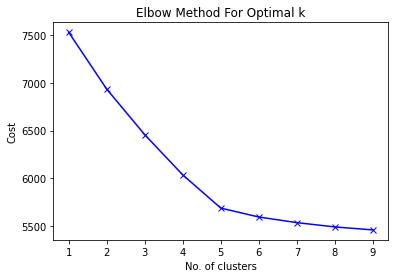

In [ ]:
plt.plot(K, cost, 'bx-')
plt.xlabel('No. of clusters')
plt.ylabel('Cost')
plt.title('Elbow Method For Optimal k')
plt.show()

In [ ]:
kl = KneeLocator(range(1, 10), cost,
            curve="convex", 
            direction="decreasing")
kl.elbow

5

Er lijken dus 5 clusters in de data te zitten.
De vraag is nu: welke?

In [ ]:
kmode = KModes(n_clusters=5, init = "random", n_init = 4, verbose=False)
clusters = kmode.fit_predict(df_analyse)

In [ ]:
unique, counts = np.unique(kmode.labels_, return_counts=True)
dict(zip(unique, counts))

{0: 2627, 1: 735, 2: 563, 3: 213, 4: 179}

In cluster 1 (0) dus 2627 personen, in cluster 2 735 etc.
<p>
We kunnen nu ook de clusterindeling aan de tabel toevoegen. 

In [ ]:
df_analyse.insert(0, "Cluster", clusters, True)
df_analyse.head()

,Cluster,income,region
0,0,800.0,Lubuskie
1,0,350.0,Podlaskie
3,0,900.0,Podlaskie
4,2,1500.0,Zachodnio-pomorskie
5,0,-8.0,Slaskie


En hoe zien de clusters er nu uit?

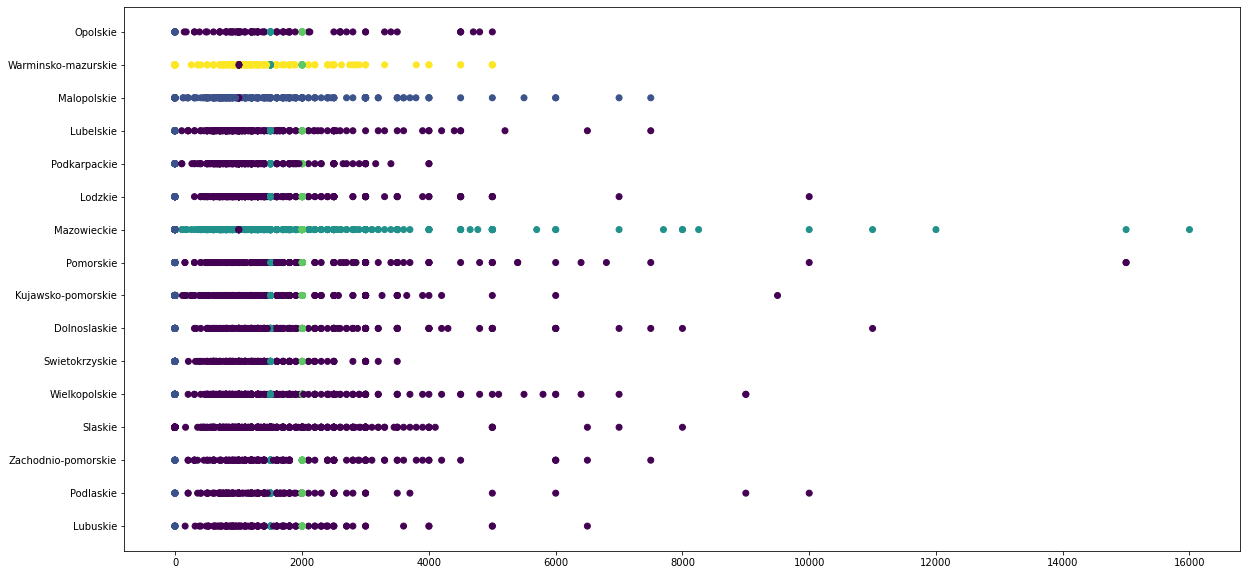

In [ ]:
plt.figure(figsize=(20,10))
plt.scatter(df_analyse['income'],df_analyse['region'], c = df_analyse['Cluster'])

Of met een ander grafiektype:

In [ ]:
fig = px.scatter(df_analyse, df_analyse['income'],df_analyse['region'],
	         color=df_analyse['Cluster'],
                 log_x=False, size_max=60)
fig.show()

We kunnen er ook een tabel van maken:

In [ ]:
a = pd.crosstab(df_analyse["Cluster"], df_analyse["region"]) 
b = pd.crosstab(df_analyse["Cluster"], df_analyse["income"])
cluster_uitkomst = a.join(b)
cluster_uitkomst 

,Dolnoslaskie,Kujawsko-pomorskie,Lodzkie,Lubelskie,Lubuskie,Malopolskie,Mazowieckie,Opolskie,Podkarpackie,Podlaskie,...,7700.0,8000.0,8255.0,9000.0,9500.0,10000.0,11000.0,12000.0,15000.0,16000.0
Cluster,,,,,,,,,,,,,,,,,,,,,
0,213,186,241,199,111,13,29,96,200,134,...,0,2,0,3,1,3,1,0,2,0
1,29,52,31,37,8,311,63,16,27,9,...,0,0,0,0,0,0,0,0,0,0
2,13,19,22,12,5,0,376,9,16,12,...,1,2,1,0,0,1,1,1,1,1
3,16,15,19,10,10,0,34,10,5,13,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
cluster_uitkomst.to_excel('cluster_uitkomst.xlsx', sheet_name='sheet1')

Conclusie?